Steps to preprocess VIIRS data for phenology tracking.

Author: Tayler LaSharr
Date: September 2024

In [27]:
## first we will read in necessary python libraries and intialize the GEE module
## you will have to authenticate GEE on your machine to use this code

import ee
import matplotlib.pyplot as plt
from datetime import datetime, timezone
import geopandas as gpd
import json
import pandas as pd
import pprint

## if you need to authenticate GEE use this code
# ee.Authenticate()

## initialize the Earth Engine module
ee.Initialize(project='ee-tlasharr')

In [28]:
## set thresholds and things to manipulate
vi_layer = 'NDVI'
snow_threshold = 30

## this is the window size to test for winter conditions
allow_missing=2
start_month_day='12-01'
end_month_day='03-01'

start_month = 12 ## start of winter
end_month = 2 ## end of winter


Projection of the cooridor shapefile: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}


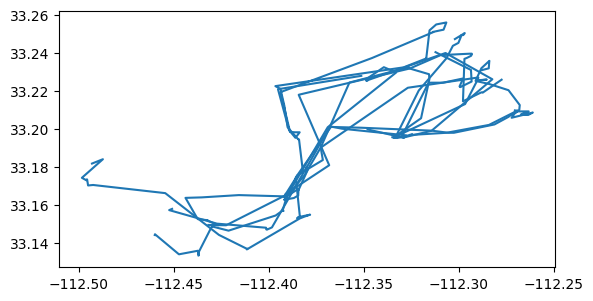

In [29]:
## load in a shapefile or area of interest
## this is an assest that is already loaded into GEE

md_cooridor = ee.FeatureCollection('projects/ee-tlasharr/assets/AZ_RainbowValley') ## dry af
# md_cooridor = ee.FeatureCollection('projects/ee-tlasharr/assets/WY_Sublette') ## "normal" temperate environment
# md_cooridor = ee.FeatureCollection('projects/ee-tlasharr/assets/UT_Paunsaugunt') ## some snow in winter

## get some random points to test things with from the MD data
random_points = ee.FeatureCollection.randomPoints(region=md_cooridor.geometry(), points=10, seed=42)
random_points_info = random_points.getInfo()['features']
point_ids = ['point_' + str(i) for i in range(10)]  # 10 unique point IDs

## load in the VIIRS data and the MODIS snow data
viirs_ndvi = ee.ImageCollection('NASA/VIIRS/002/VNP13A1') \
                .filterDate('2018-01-01', '2023-12-31') \
                .select('NDVI')

viirs_evi = ee.ImageCollection('NASA/VIIRS/002/VNP13A1') \
                .filterDate('2018-01-01', '2023-12-31') \
                .select('EVI')

## right now i'm using the modis snow layer for processing snow, but VIIRS does have one, it's just not yet
## available for GEE

modis_snow = ee.ImageCollection('MODIS/006/MOD10A1') \
                .filterDate('2018-01-01', '2023-12-31') \
                .select('NDSI_Snow_Cover')

## first see the projection of the shapefile
coordidor_projection = md_cooridor.first().geometry().projection()
print('Projection of the cooridor shapefile:', coordidor_projection.getInfo())

## now we can reproject the shapefile
viirs_projection = viirs_ndvi.first().projection() ## this is the projection of the first image of the modis ndvi data
target_crs = viirs_projection.crs() ## this is the crs from the modis.projection object
target_crs_scale = viirs_projection.nominalScale() ## this is the scale (confused on what this is need to figure this out)

## this is a function to reproject it
def reproject_feature(feature):
    return feature.setGeometry(feature.geometry().transform(target_crs, target_crs_scale))

## this is running the function, so now "reprojected_roi" is the new object we care about
reprojected_roi = md_cooridor.map(reproject_feature)

## then plot it, just to see what's up
geojson = md_cooridor.getInfo()
gdf = gpd.GeoDataFrame.from_features(geojson['features'])
gdf.plot()
plt.show()               

Step 1. Maintain High Quality Pixels and filter out areas with >50% snow and ice.

In [30]:
## deal with cloud cover and low-quality observations by defining an NDVI threshold to filter out invalid values (e.g., NDVI values between -0.1 and 1)
def ndvi_quality_mask(image, vi_layer = 'NDVI'):
    ndvi = image.select(vi_layer)
    return image.updateMask(ndvi.gt(-0.1).And(ndvi.lt(1)))

## deal with snow cover
def dynamic_snow_mask(image):
    image_date = ee.Date(image.get('system:time_start'))
    snow_image = modis_snow.filterDate(image_date, image_date.advance(1, 'day')).mean()  # Filter snow for the same date
    snow_mask = snow_image.gt(snow_threshold)
    return image.updateMask(snow_mask.Not())


## apply the NDVI mask to filter out low-quality NDVI values
viirs_ndvi_filtered = viirs_ndvi.map(ndvi_quality_mask).map(dynamic_snow_mask)


Step 2. Set winter baselines dynamically since winter conditions are variable year to year. This differs from the Bischof methods because winter is not consistent and some winters have snow while others do not.

In [31]:
## function to calculate the winter baseline dynamically
def calculate_winter_baseline(image_collection, quantile=0.025, start_month=12, end_month=2):
    
    ## filter NDVI images to only the winter months defined by the user
    if start_month <= end_month:
        ## if winter doesn't cross the year boundary (e.g., November to December)
        winter_ndvi = image_collection.filter(ee.Filter.calendarRange(start_month, end_month, 'month'))
    else:
        ## if winter crosses the year boundary (e.g., December to February)
        winter_ndvi = image_collection.filter(
            ee.Filter.Or(
                ee.Filter.calendarRange(start_month, 12, 'month'),
                ee.Filter.calendarRange(1, end_month, 'month')
            )
        )
    
    ## calculate the specified lower quantile (e.g., 0.025) of NDVI for each pixel during winter
    winter_baseline = winter_ndvi.reduce(ee.Reducer.percentile([quantile * 100]))
    
    return winter_baseline

## function to adjust NDVI values below the winter baseline
def adjust_ndvi_for_winter(image, baseline, vi_layer = 'NDVI'):
    ndvi = image.select(vi_layer)
    
    ## ensure NDVI values below the baseline are set to the baseline
    adjusted_ndvi = ndvi.max(baseline)
    
    ## return the image with the adjusted NDVI values
    return image.addBands(adjusted_ndvi.rename('NDVI_adjusted'), overwrite=True)

## function to check for consistent snow cover using a moving window
def check_consistent_snow_for_years(snow_masked_collection, start_month_day, end_month_day, snow_threshold=50, allow_missing=2):
    
    def consistent_snow(image):
        ## get the year of the image
        year = ee.Date(image.get('system:time_start')).get('year')

        ## create date ranges for each winter period using the specified months and days
        start_date = ee.Date.fromYMD(year, ee.Number.parse(start_month_day.split('-')[0]), ee.Number.parse(start_month_day.split('-')[1]))
        end_date = ee.Date.fromYMD(year.add(1), ee.Number.parse(end_month_day.split('-')[0]), ee.Number.parse(end_month_day.split('-')[1]))

        ## filter the snow_masked_collection to the winter period for the current year
        snow_in_period = snow_masked_collection.filterDate(start_date, end_date)

        ## for each pixel, count the number of snow-covered days in the period
        def count_snow_days(img):
            snow_days = img.select('NDSI_Snow_Cover').gt(snow_threshold)
            return snow_days

        ## apply the snow cover threshold across the period
        snow_days_in_period = snow_in_period.map(count_snow_days)

        ## sum the number of snow-covered days for each pixel in the period
        snow_days_count = snow_days_in_period.reduce(ee.Reducer.sum())

        ## calculate the total number of days in the time period
        total_days = end_date.difference(start_date, 'day')

        ## if more than (total_days - allow_missing) days are snow-covered, consider it consistent snow cover
        consistent = snow_days_count.gte(total_days.subtract(allow_missing))

        ## create a mask where pixels have consistent snow cover during the time period
        return image.updateMask(consistent)

    ## apply the consistent snow check to the entire image collection
    consistent_snow_masked = snow_masked_collection.map(consistent_snow)

    return consistent_snow_masked

## function to adjust the missing NDVI values within a certain date range
def adjust_missing_values(image, baseline, start_date, end_date):
    ndvi = image.select('NDVI')
    missing_mask = ndvi.mask().Not()  # Mask for missing NDVI values
    
    ## get the image date
    image_date = ee.Date(image.get('system:time_start'))

    ## check if the image date falls within the start and end dates using logical conditions
    is_in_winter_period = image_date.difference(start_date, 'day').gte(0).And(image_date.difference(end_date, 'day').lte(0))

    ## apply the winter baseline if the date is within the period and there's missing data
    adjusted_ndvi = ndvi.where(missing_mask.And(is_in_winter_period), baseline)
    
    return image.addBands(adjusted_ndvi.rename('NDVI_adjusted'), overwrite=True)

## function to apply everything dynamically
def process_ndvi_with_dynamic_winter(image_collection, start_month=12, end_month=2, 
                                     quantile=0.025, baseline_start_offset=-65, 
                                     baseline_end_offset=60,
                                     start_date='2018-01-01',
                                     end_date='2023-02-28'): 

    ## calculate winter baseline dynamically based on the provided winter months
    winter_baseline_ndvi = calculate_winter_baseline(image_collection, quantile=quantile, start_month=start_month, end_month=end_month)
    
    ## adjust the NDVI values below the baseline
    viirs_ndvi_adjusted = image_collection.map(lambda image: adjust_ndvi_for_winter(image, winter_baseline_ndvi))
    
    ## set start and end dates for handling missing data points around the turn of the year
    start_of_year = ee.Date(start_date) 
    end_of_year = ee.Date(end_date) 
    
    ## apply the adjustment for missing values around the turn of the year
    viirs_ndvi_adjusted_with_missing = viirs_ndvi_adjusted.map(
        lambda image: adjust_missing_values(image, winter_baseline_ndvi,
                                            start_of_year.advance(baseline_start_offset, 'day'),
                                            end_of_year.advance(baseline_end_offset, 'day'))
    )
    
    return viirs_ndvi_adjusted_with_missing

## get the processed NDVI data
processed_ndvi = process_ndvi_with_dynamic_winter(viirs_ndvi, start_month=12, end_month=2, quantile=0.025,
                                                  start_date='2018-01-01', end_date='2023-12-31')




Step 3. Apply a smoothing function (moving median window with a search window of 3)

In [32]:


def apply_temporal_median(image_collection, window_size=3):
    
    ## define a function to apply the temporal moving median for each image
    def smooth_image(image):
        
        ## get the date of the current image
        image_date = ee.Date(image.get('system:time_start'))
        
        ## calculate the number of images before and after the current image
        half_window = (window_size // 2)
        
        ## create a filter that selects images within the window size based on system:time_start
        start_date = image_date.advance(-half_window, 'month')  # Adjust to 'month' for smoother non-daily data
        end_date = image_date.advance(half_window, 'month')
        
        ## filter the image collection by this date window
        window = image_collection.filterDate(start_date, end_date)
        
        ## compute the median of the images in the window
        median_image = window.median()
        
        ## return the median-smoothed image while keeping the original properties
        return median_image.copyProperties(image, image.propertyNames())
    
    ## apply the smoothing function over the entire image collection
    smoothed_collection = image_collection.map(smooth_image)
    
    return smoothed_collection

## apply the temporal smoothing function to the processed_ndvi collection
smoothed_ndvi = apply_temporal_median(processed_ndvi, window_size=3)

In [33]:
## function to extract NDVI values for multiple random points from an image collection
def extract_ndvi_for_points(image_collection, points):
    
    def extract_for_point(image):
        
        ## iterate over the points (FeatureCollection) and extract NDVI for each point
        def extract_for_feature(feature):

            ## reduce the region for each point and get the mean NDVI value
            ndvi_value = image.reduceRegion(
                reducer=ee.Reducer.mean(),
                geometry=feature.geometry(),
                scale=500 
            )

            date = ee.Date(image.get('system:time_start')).format('YYYY-MM-dd')
            return feature.set({'NDVI': ndvi_value.get('NDVI'), 'date': date})

        ## map the function over all points
        return points.map(extract_for_feature)

    ## apply the extraction function over the entire image collection
    ## note: we flattened the results so they return as one FeatureCollection
    ndvi_values = image_collection.map(extract_for_point).flatten()
    
    return ndvi_values


## extract NDVI values for random points from each collection
smoothed_ndvi_values = extract_ndvi_for_points(smoothed_ndvi, random_points)
processed_ndvi_values = extract_ndvi_for_points(processed_ndvi, random_points)
viirs_ndvi_values = extract_ndvi_for_points(viirs_ndvi, random_points)


In [34]:
smoothed_ndvi_values_info = smoothed_ndvi_values.getInfo()
processed_ndvi_values_info = processed_ndvi_values.getInfo()
viirs_ndvi_values_info = viirs_ndvi_values.getInfo()

## get the infomration from the random_points object
random_points_info = random_points.getInfo()['features']

## function to get dataframes
def convert_to_dataframe(ndvi_values_info, point_ids):
    
    ## create a list to hold the processed data
    data = []
    
    ## loop through each feature and extract the NDVI and date properties for each point
    for i, point_id in enumerate(point_ids):
        
        ## get the corresponding features for the current point
        
        for feature in ndvi_values_info['features']:
            
            ## extract NDVI and date from properties
            properties = feature.get('properties', {})
            ndvi = properties.get('NDVI', None)
            date_str = properties.get('date')

            ## parse the date string
            try:
                date = datetime.strptime(date_str, '%Y-%m-%d')  ## convert to datetime object
            except:
                date = None  ## if the parsing fails, set the date as None

            ## add the extracted data along with the point_id
            if ndvi is not None and date is not None:
                data.append({'date': date, 'NDVI': ndvi, 'point_id': point_id})
    
    ## convert the list into a Pandas DataFrame
    ndvi_df = pd.DataFrame(data)
    
    ## remove duplicates (same point, same date) by keeping only the first occurrence
    ndvi_df = ndvi_df.drop_duplicates(subset=['date', 'point_id'])
    
    ## sort the DataFrame by point_id and date
    ndvi_df = ndvi_df.sort_values(by=['point_id', 'date'])

    return ndvi_df


## convert the NDVI values to DataFrames for each collection
smoothed_ndvi_df = convert_to_dataframe(smoothed_ndvi_values_info, point_ids)
processed_ndvi_df = convert_to_dataframe(processed_ndvi_values_info, point_ids)
viirs_ndvi_df = convert_to_dataframe(viirs_ndvi_values_info, point_ids)

## print the first few rows of the DataFrames to verify
print(smoothed_ndvi_df.head())
print(processed_ndvi_df.head())
print(viirs_ndvi_df.head())

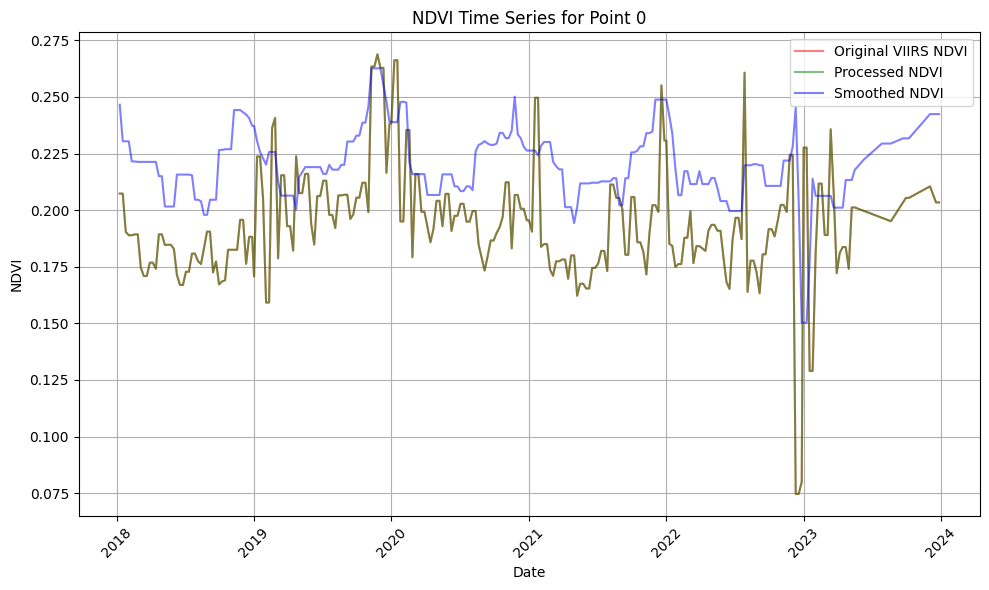

In [26]:
## subset the data to get the first point
smoothed_point_0_df = smoothed_ndvi_df[smoothed_ndvi_df['point_id'] == 'point_0']
processed_point_0_df = processed_ndvi_df[processed_ndvi_df['point_id'] == 'point_0']
viirs_point_0_df = viirs_ndvi_df[viirs_ndvi_df['point_id'] == 'point_0']

## function to plot NDVI time series for one point
def plot_ndvi(df, title, color):
    plt.plot(df['date'], df['NDVI'], linestyle='-', label=title, color=color)

## plot the NDVI time series for the first point from each DataFrame
plt.figure(figsize=(10, 6))

## plot original VIIRS NDVI
plt.plot(viirs_point_0_df['date'], viirs_point_0_df['NDVI'], label='Original VIIRS NDVI', color='red', alpha=0.5, linestyle='-')

##  processed NDVI (snow and bad data removed)
plt.plot(processed_point_0_df['date'], processed_point_0_df['NDVI'], label='Processed NDVI', color='green', alpha=0.5, linestyle='-')

## smoothed data
plt.plot(smoothed_point_0_df['date'], smoothed_point_0_df['NDVI'], label='Smoothed NDVI', color='blue', alpha=0.5, linestyle='-')


## add titles and labels
plt.title('NDVI Time Series for Point 0')
plt.xlabel('Date')
plt.ylabel('NDVI')
plt.legend()
plt.grid(True)

## show the plot
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()